<a href="https://colab.research.google.com/github/pontonganronald-byte/kristineportfolio/blob/main/PontonganQuiz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.metrics import (accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, mean_squared_error)

RANDOM_STATE = 42
BASELINE_NOISE = 0.22
BASELINE_DEPTH = 3
BASELINE_LEAF = 1
BASELINE_REG_DEPTH = 4
plt.rcParams.update({'figure.dpi': 100, 'axes.grid': False})
print('Ready. All datasets in this notebook are synthetic and reproducible.')

Ready. All datasets in this notebook are synthetic and reproducible.


In [19]:
def classification_data(noise=BASELINE_NOISE):
    X, y = make_moons(n_samples=450, noise=noise, random_state=RANDOM_STATE)
    return train_test_split(X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y)

def classification_model(X_train, y_train, depth=BASELINE_DEPTH, leaf=BASELINE_LEAF):
    return DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf,
                                  criterion='gini', random_state=RANDOM_STATE).fit(X_train, y_train)

def classification_scores(model, X_train, X_test, y_train, y_test):
    return {'train_accuracy': accuracy_score(y_train, model.predict(X_train)),
            'test_accuracy': accuracy_score(y_test, model.predict(X_test)),
            'nodes': model.tree_.node_count,
            'leaves': model.get_n_leaves()}

def draw_boundary(model, X, y, title, ax=None):
    if ax is None: _, ax = plt.subplots(figsize=(6, 4))
    x0, x1 = X[:, 0], X[:, 1]
    xx, yy = np.meshgrid(np.linspace(x0.min()-.5, x0.max()+.5, 230),
                         np.linspace(x1.min()-.5, x1.max()+.5, 230))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.23, cmap='coolwarm')
    ax.scatter(x0, x1, c=y, s=13, cmap='coolwarm', edgecolors='none', alpha=.75)
    ax.set(title=title, xlabel='Feature 1', ylabel='Feature 2')
    return ax

def regression_data():
    rng = np.random.default_rng(RANDOM_STATE)
    x = np.sort(6 * rng.random(220))
    y = np.sin(1.5*x) + .25*np.cos(3*x) + rng.normal(0, .23, size=x.shape)
    X = x.reshape(-1, 1)
    return train_test_split(X, y, test_size=.30, random_state=RANDOM_STATE)

def regression_model(X_train, y_train, depth=BASELINE_REG_DEPTH):
    return DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE).fit(X_train, y_train)

def regression_rmse(model, X, y):
    return np.sqrt(mean_squared_error(y, model.predict(X)))

def draw_regression_curve(model, X_train, y_train, X_test, y_test, title, ax=None):
    if ax is None: _, ax = plt.subplots(figsize=(7, 4))
    xx = np.linspace(0, 6, 600).reshape(-1, 1)
    ax.scatter(X_train[:,0], y_train, s=17, alpha=.53, label='Training samples')
    ax.scatter(X_test[:,0], y_test, s=18, alpha=.64, label='Test samples', marker='x')
    ax.plot(xx[:,0], model.predict(xx), color='black', linewidth=2, label='Tree prediction')
    ax.set(title=title, xlabel='Input feature', ylabel='Target')
    ax.legend(fontsize=8)
    return ax

X_train, X_test, y_train, y_test = classification_data()
classifier = classification_model(X_train, y_train)
Xr_train, Xr_test, yr_train, yr_test = regression_data()
regressor = regression_model(Xr_train, yr_train)
print('Classification split:', len(X_train), 'training /', len(X_test), 'test samples')
print('Regression split:', len(Xr_train), 'training /', len(Xr_test), 'test samples')

Classification split: 315 training / 135 test samples
Regression split: 154 training / 66 test samples


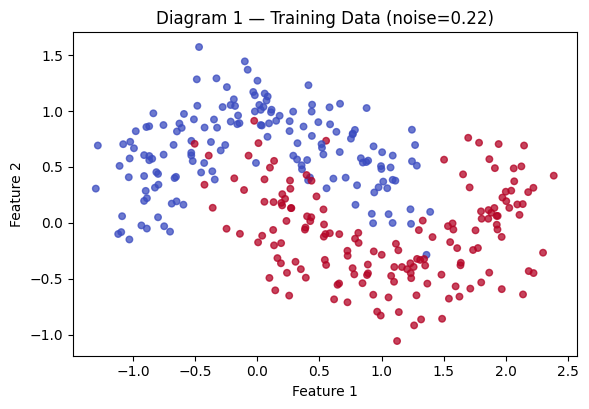

In [20]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(X_train[:,0], X_train[:,1], c=y_train, cmap='coolwarm', s=22, alpha=.75)
ax.set(title=f'Diagram 1 — Training Data (noise={BASELINE_NOISE})', xlabel='Feature 1', ylabel='Feature 2')
plt.show()

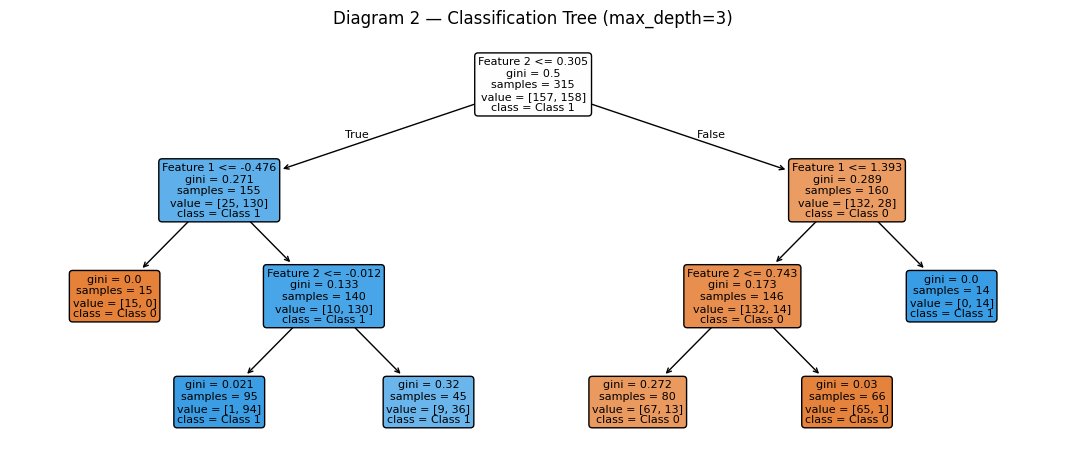

Baseline classification: {'train_accuracy': 0.9238095238095239, 'test_accuracy': 0.9037037037037037, 'nodes': 11, 'leaves': np.int64(6)}


In [21]:
fig, ax = plt.subplots(figsize=(13.5, 5.5))
plot_tree(classifier, max_depth=3, filled=True, rounded=True, fontsize=8,
          feature_names=['Feature 1','Feature 2'], class_names=['Class 0','Class 1'], ax=ax)
ax.set_title(f'Diagram 2 — Classification Tree (max_depth={BASELINE_DEPTH})')
plt.show()
print('Baseline classification:', classification_scores(classifier, X_train, X_test, y_train, y_test))

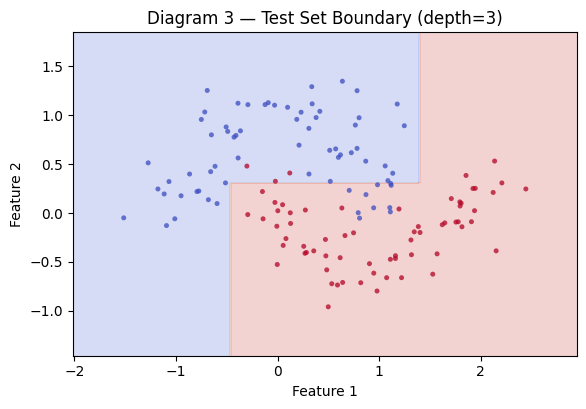

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
draw_boundary(classifier, X_test, y_test, f'Diagram 3 — Test Set Boundary (depth={BASELINE_DEPTH})', ax=ax)
plt.show()

,max_depth,train_accuracy,test_accuracy,leaves
0,1,0.832,0.807,2
1,2,0.924,0.904,4
2,3,0.924,0.904,6
3,4,0.930,0.904,10
4,5,0.946,0.911,15
5,6,0.978,0.963,18
6,7,0.984,0.956,22
7,8,0.994,0.956,25
8,9,0.997,0.956,27
9,10,1.000,0.948,28


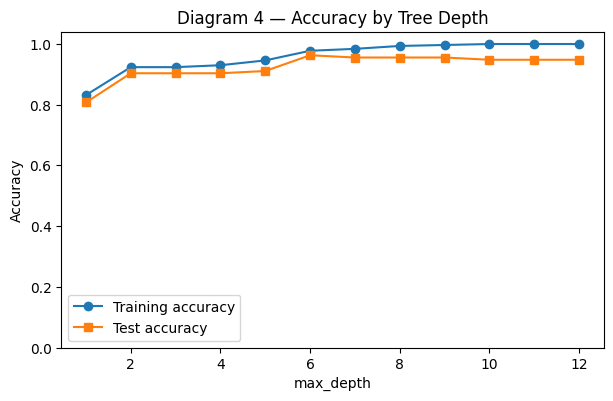

In [6]:
depth_results=[]
for depth in range(1, 13):
    m=classification_model(X_train, y_train, depth=depth)
    r=classification_scores(m, X_train, X_test, y_train, y_test)
    depth_results.append({'max_depth': depth, **r})
depth_df=pd.DataFrame(depth_results)
display(depth_df[['max_depth','train_accuracy','test_accuracy','leaves']].round(3))
fig, ax=plt.subplots(figsize=(7,4.1))
ax.plot(depth_df.max_depth, depth_df.train_accuracy, 'o-', label='Training accuracy')
ax.plot(depth_df.max_depth, depth_df.test_accuracy, 's-', label='Test accuracy')
ax.set(title='Diagram 4 — Accuracy by Tree Depth', xlabel='max_depth', ylabel='Accuracy', ylim=(0,1.04))
ax.legend(); plt.show()

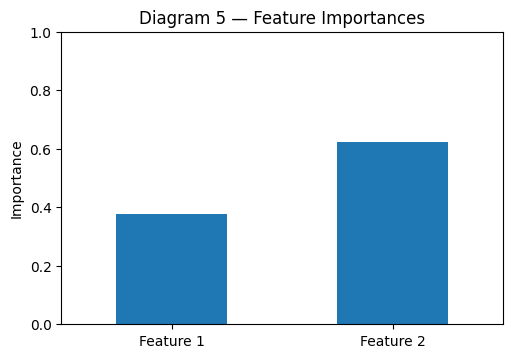

Feature 1    0.377
Feature 2    0.623


In [7]:
importance=pd.Series(classifier.feature_importances_, index=['Feature 1','Feature 2'])
fig, ax=plt.subplots(figsize=(5.7,3.8))
importance.plot(kind='bar', ax=ax)
ax.set(title='Diagram 5 — Feature Importances', ylabel='Importance', ylim=(0,1))
plt.xticks(rotation=0); plt.show()
print(importance.round(3).to_string())

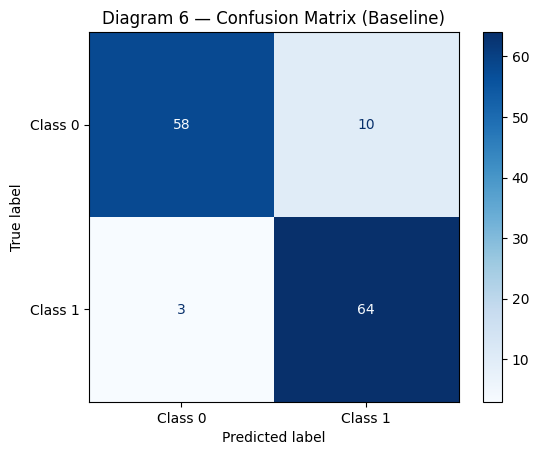

              precision    recall  f1-score   support

           0       0.95      0.85      0.90        68
           1       0.86      0.96      0.91        67

    accuracy                           0.90       135
   macro avg       0.91      0.90      0.90       135
weighted avg       0.91      0.90      0.90       135



In [8]:
yp=classifier.predict(X_test)
ConfusionMatrixDisplay.from_predictions(y_test, yp, display_labels=['Class 0','Class 1'], cmap='Blues', values_format='d')
plt.title('Diagram 6 — Confusion Matrix (Baseline)'); plt.show()
print(classification_report(y_test, yp, zero_division=0))

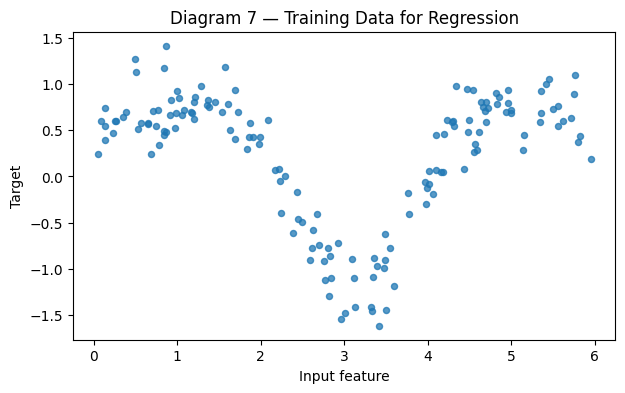

In [9]:
fig, ax=plt.subplots(figsize=(7,4))
ax.scatter(Xr_train[:,0], yr_train, s=19, alpha=.75)
ax.set(title='Diagram 7 — Training Data for Regression', xlabel='Input feature', ylabel='Target')
plt.show()

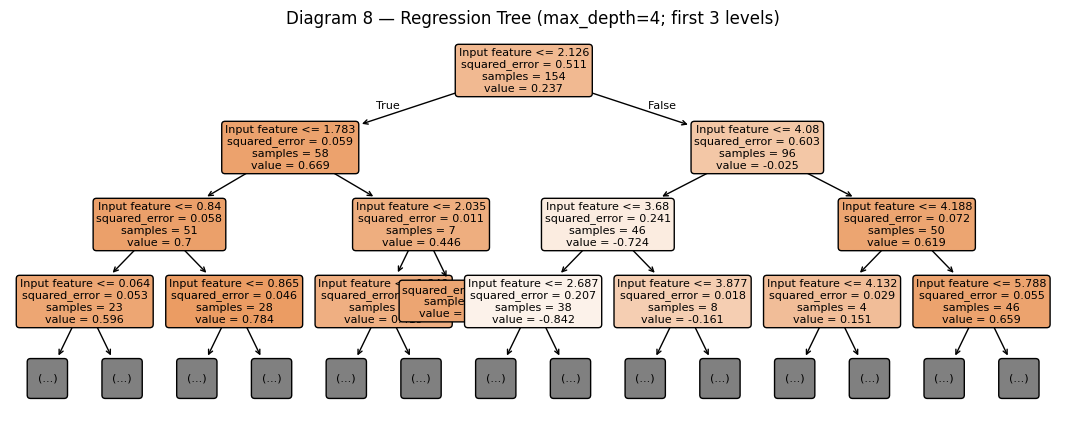

In [10]:
fig, ax=plt.subplots(figsize=(13.5,5))
plot_tree(regressor, max_depth=3, filled=True, rounded=True, fontsize=8, feature_names=['Input feature'], ax=ax)
ax.set_title(f'Diagram 8 — Regression Tree (max_depth={BASELINE_REG_DEPTH}; first 3 levels)')
plt.show()

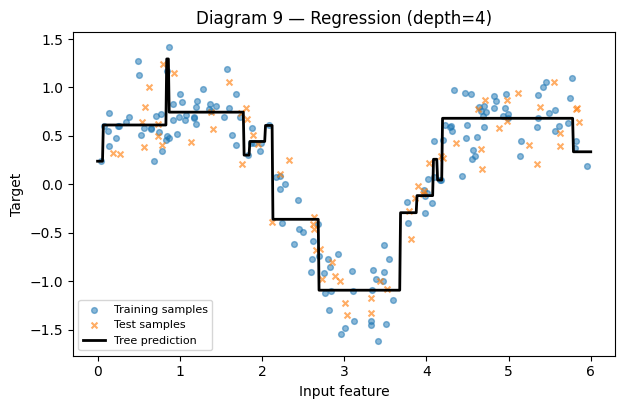

Baseline train RMSE: 0.221
Baseline test RMSE: 0.28


In [11]:
fig, ax=plt.subplots(figsize=(7,4.2))
draw_regression_curve(regressor, Xr_train, yr_train, Xr_test, yr_test,
                      f'Diagram 9 — Regression (depth={BASELINE_REG_DEPTH})', ax=ax)
plt.show()
print('Baseline train RMSE:', round(regression_rmse(regressor, Xr_train, yr_train),3))
print('Baseline test RMSE:', round(regression_rmse(regressor, Xr_test, yr_test),3))

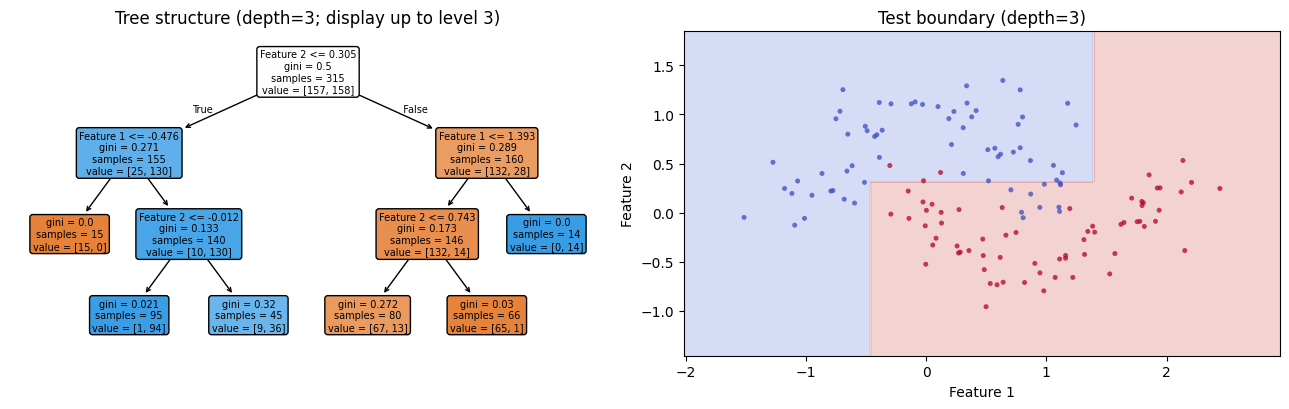

,depth,train_accuracy,test_accuracy,nodes,leaves
0,3,0.924,0.904,11,6


In [12]:
# CHALLENGE 1 — STUDENT MODIFICATION
# TODO: change [3] to [1, 3, 8]
depths = [3]
results=[]
for d in depths:
    m=classification_model(X_train, y_train, depth=d)
    r=classification_scores(m, X_train, X_test, y_train, y_test)
    results.append({'depth':d, **r})
    fig, axes=plt.subplots(1,2,figsize=(13,4.2))
    plot_tree(m, max_depth=3, filled=True, rounded=True, fontsize=7,
              feature_names=['Feature 1','Feature 2'], ax=axes[0])
    axes[0].set_title(f'Tree structure (depth={d}; display up to level 3)')
    draw_boundary(m, X_test, y_test, f'Test boundary (depth={d})', axes[1])
    plt.tight_layout(); plt.show()
display(pd.DataFrame(results).round(3))

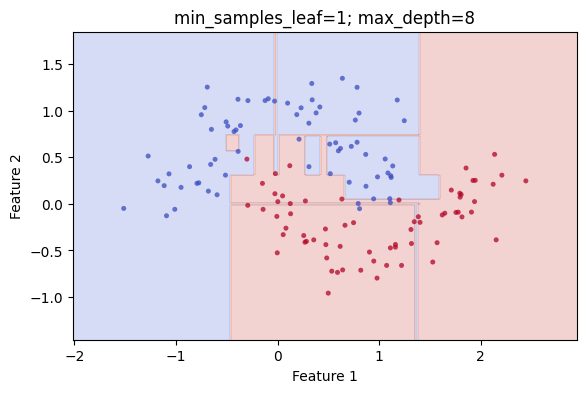

,min_samples_leaf,train_accuracy,test_accuracy,nodes,leaves
0,1,0.994,0.956,49,25


In [13]:
# CHALLENGE 2 — STUDENT MODIFICATION
# TODO: change [1] to [1, 5, 15]
leaf_values = [1]
results=[]
for leaf in leaf_values:
    m=classification_model(X_train, y_train, depth=8, leaf=leaf)
    r=classification_scores(m, X_train, X_test, y_train, y_test)
    results.append({'min_samples_leaf':leaf, **r})
    fig, ax=plt.subplots(figsize=(6.5,4))
    draw_boundary(m, X_test, y_test, f'min_samples_leaf={leaf}; max_depth=8', ax)
    plt.show()
display(pd.DataFrame(results).round(3))

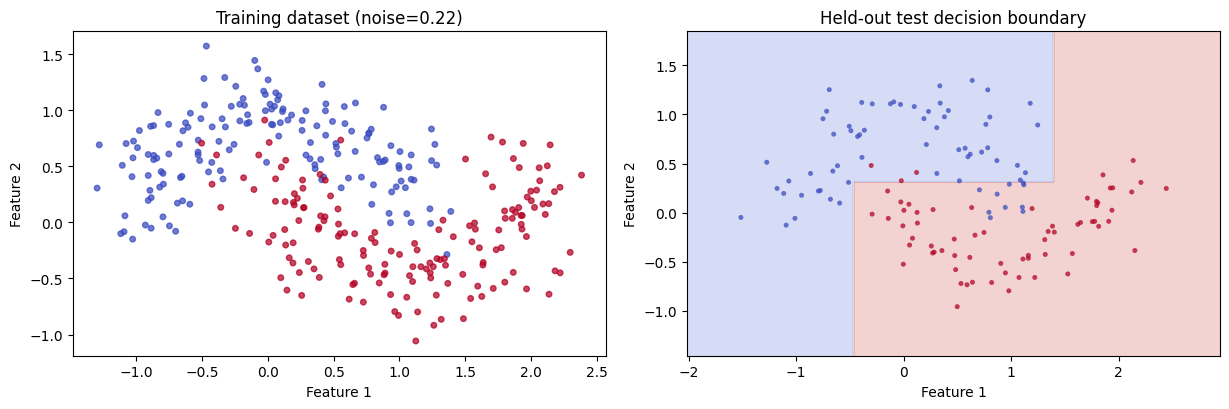

Baseline noise: 0.22 | modified noise: 0.22
New-data scores: {'train_accuracy': 0.9238095238095239, 'test_accuracy': 0.9037037037037037, 'nodes': 11, 'leaves': np.int64(6)}


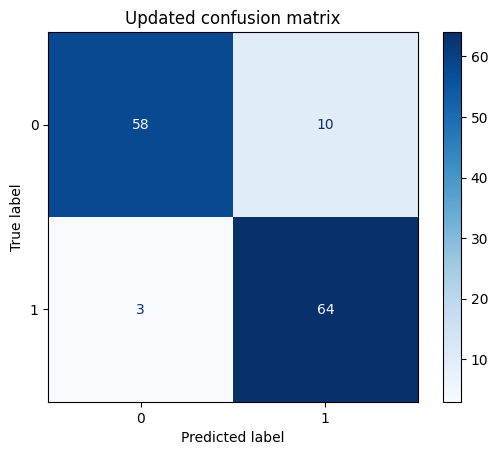

In [14]:
# CHALLENGE 3 — STUDENT MODIFICATION
# TODO: change modified_noise from 0.22 to 0.38
modified_noise = 0.22
Xa, Xb, ya, yb = classification_data(noise=modified_noise)
changed=classification_model(Xa, ya, depth=BASELINE_DEPTH)
fig, axes=plt.subplots(1,2,figsize=(12.4,4.2))
axes[0].scatter(Xa[:,0], Xa[:,1], c=ya, cmap='coolwarm', s=16, alpha=.73)
axes[0].set(title=f'Training dataset (noise={modified_noise})', xlabel='Feature 1', ylabel='Feature 2')
draw_boundary(changed, Xb, yb, 'Held-out test decision boundary', axes[1])
plt.tight_layout(); plt.show()
print('Baseline noise:', BASELINE_NOISE, '| modified noise:', modified_noise)
print('New-data scores:', classification_scores(changed, Xa, Xb, ya, yb))
ConfusionMatrixDisplay.from_predictions(yb, changed.predict(Xb), cmap='Blues', values_format='d')
plt.title('Updated confusion matrix'); plt.show()

Depth 3: TN=58, FP=10, FN=3, TP=64; test accuracy=0.904
              precision    recall  f1-score   support

           0       0.95      0.85      0.90        68
           1       0.86      0.96      0.91        67

    accuracy                           0.90       135
   macro avg       0.91      0.90      0.90       135
weighted avg       0.91      0.90      0.90       135



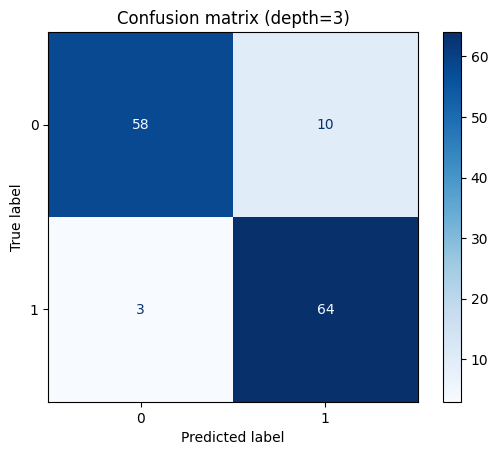

In [15]:
# CHALLENGE 4 — STUDENT MODIFICATION
# TODO: change [3] to [2, 8]
matrix_depths = [3]
for d in matrix_depths:
    m=classification_model(X_train, y_train, depth=d)
    p=m.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, p, labels=[0,1]).ravel()
    print(f'Depth {d}: TN={tn}, FP={fp}, FN={fn}, TP={tp}; test accuracy={accuracy_score(y_test,p):.3f}')
    print(classification_report(y_test,p,zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test,p,labels=[0,1],cmap='Blues',values_format='d')
    plt.title(f'Confusion matrix (depth={d})'); plt.show()

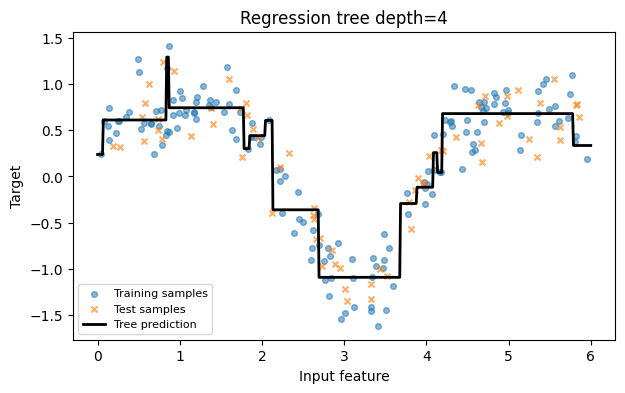

,depth,leaves,train_rmse,test_rmse
0,4,15,0.221,0.28


In [16]:
# CHALLENGE 5 — STUDENT MODIFICATION
# TODO: change [4] to [2, 4, 10]
regression_depths = [4]
results=[]
for d in regression_depths:
    m=regression_model(Xr_train, yr_train, depth=d)
    results.append({'depth': d, 'leaves': m.get_n_leaves(),
                    'train_rmse': regression_rmse(m, Xr_train, yr_train),
                    'test_rmse': regression_rmse(m, Xr_test, yr_test)})
    fig, ax=plt.subplots(figsize=(7,4))
    draw_regression_curve(m, Xr_train, yr_train, Xr_test, yr_test, f'Regression tree depth={d}', ax)
    plt.show()
display(pd.DataFrame(results).round(3))